# Lab - EDA Univariate Analysis: Amazon UK Product Insights

**Objective:** explore the product listing dynamics on Amazon UK (categories, prices, ratings) to extract actionable business insights on product positioning, pricing strategy, and inventory management.

**Dataset:** [Amazon UK Products Dataset 2023](https://www.kaggle.com/datasets/asaniczka/amazon-uk-products-dataset-2023) — 2,222,742 products, 10 columns.


## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


In [2]:
# Load the dataset
df = pd.read_csv("amz_uk_processed_data.csv")
print(df.shape)
df.head()


(2222742, 10)


,asin,title,imgUrl,productURL,stars,reviews,price,isBestSeller,boughtInLastMonth,categoryName
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/71C3lbbeLs...,https://www.amazon.co.uk/dp/B09B96TG33,4.7,15308,21.99,False,0,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",https://m.media-amazon.com/images/I/61c5rSxwP0...,https://www.amazon.co.uk/dp/B01HTH3C8S,4.7,98099,23.99,True,0,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",https://m.media-amazon.com/images/I/61j3SEUjMJ...,https://www.amazon.co.uk/dp/B09B8YWXDF,4.7,15308,21.99,False,0,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",https://m.media-amazon.com/images/I/71yf6yTNWS...,https://www.amazon.co.uk/dp/B09B8T5VGV,4.7,7205,31.99,False,0,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,https://m.media-amazon.com/images/I/613dEoF9-r...,https://www.amazon.co.uk/dp/B09WX6QD65,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2222742 entries, 0 to 2222741
Data columns (total 10 columns):
 #   Column             Dtype  
---  ------             -----  
 0   asin               object 
 1   title              object 
 2   imgUrl             object 
 3   productURL         object 
 4   stars              float64
 5   reviews            int64  
 6   price              float64
 7   isBestSeller       bool   
 8   boughtInLastMonth  int64  
 9   categoryName       object 
dtypes: bool(1), float64(2), int64(2), object(5)
memory usage: 154.7+ MB


**Note on column names:** this dataset uses `stars` for the product rating (not `rating`) and `categoryName` for the category (not `category`). These names will be used throughout the notebook.

In [4]:
# Quick sanity check: missing values and basic stats
df.isna().sum()


asin                 0
title                0
imgUrl               0
productURL           0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
categoryName         0
dtype: int64

---
## Part 1: Understanding Product Categories

**Business Question:** What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?


### 1. Frequency Table

In [5]:
category_counts = df["categoryName"].value_counts()
category_freq_table = category_counts.reset_index()
category_freq_table.columns = ["categoryName", "count"]
category_freq_table["percentage"] = (category_freq_table["count"] / len(df) * 100).round(2)
category_freq_table.head(20)


,categoryName,count,percentage
0,Sports & Outdoors,826076,37.16
1,Skin Care,18755,0.84
2,Fragrances,18563,0.84
3,Make-up,18453,0.83
4,Manicure & Pedicure Products,17212,0.77
5,"Handmade Clothing, Shoes & Accessories",16707,0.75
6,Men,16384,0.74
7,Women,16284,0.73
8,Handmade Gifts,15790,0.71
9,Handmade Artwork,15297,0.69


In [6]:
top5_categories = category_counts.head(5)
print("Top 5 most listed categories:")
top5_categories


Top 5 most listed categories:


categoryName
Sports & Outdoors               826076
Skin Care                        18755
Fragrances                       18563
Make-up                          18453
Manicure & Pedicure Products     17212
Name: count, dtype: int64

**Interpretation:**
- "Sports & Outdoors" is by far the most listed category, with **826,076 listings (37.16% of the entire catalog)** — more than 44x the size of the next category (Skin Care, 0.84%).
- The other top categories (Skin Care, Fragrances, Make-up, Manicure & Pedicure Products, Handmade goods, etc.) each represent under 1% of listings individually.
- This points to an extremely concentrated catalog dominated by one category, with a very long tail of small, fragmented categories. This scale of dominance (37% in one bucket vs <1% for everything else) is also worth flagging as a possible categorization/data quality artifact — "Sports & Outdoors" may be acting as a catch-all category for loosely-classified products, which a real business analysis should verify before drawing conclusions.


### 2. Visualizations

C:\Users\pc\AppData\Local\Temp\ipykernel_10944\2403031468.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, palette="viridis")


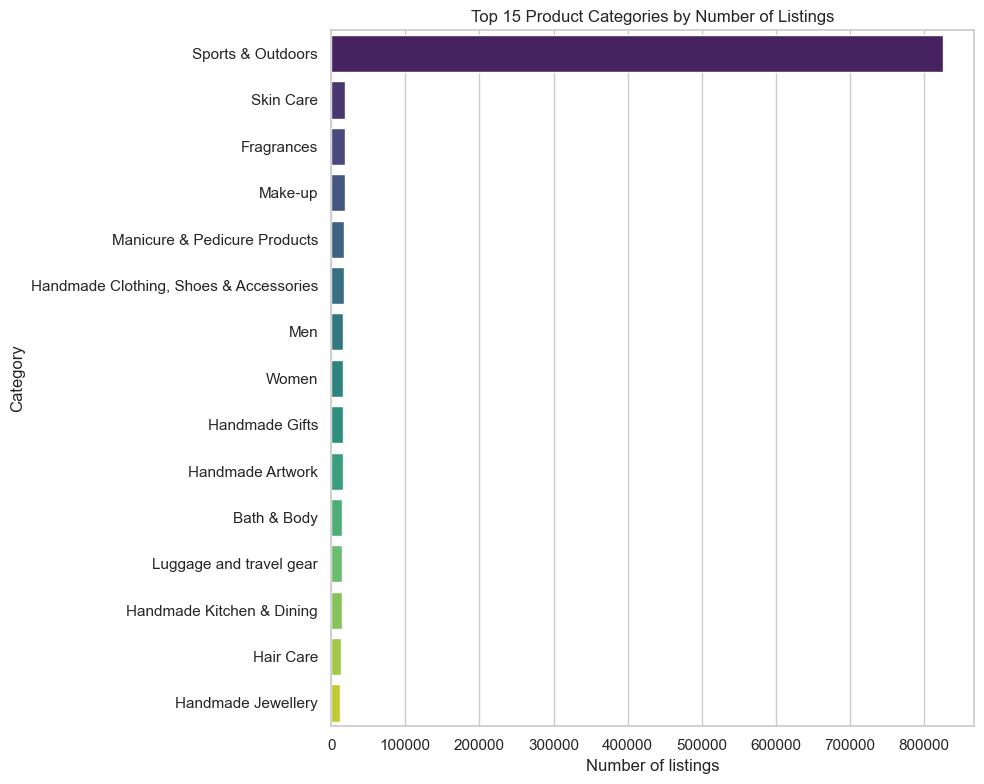

In [7]:
# Bar chart - top 15 categories (all categories would be unreadable, there are usually hundreds)
top_n = 15
top_categories = category_counts.head(top_n)

plt.figure(figsize=(10, 8))
sns.barplot(x=top_categories.values, y=top_categories.index, palette="viridis")
plt.title(f"Top {top_n} Product Categories by Number of Listings")
plt.xlabel("Number of listings")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


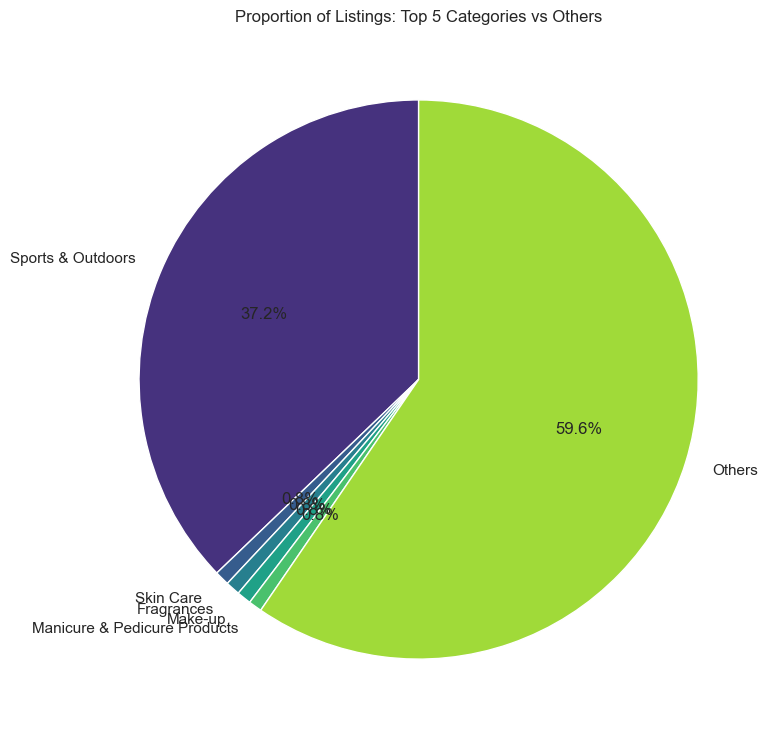

In [8]:
# Pie chart - top 5 categories vs "Others"
top5 = category_counts.head(5)
others_total = category_counts.iloc[5:].sum()

pie_data = pd.concat([top5, pd.Series({"Others": others_total})])

plt.figure(figsize=(8, 8))
plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("viridis", len(pie_data)),
)
plt.title("Proportion of Listings: Top 5 Categories vs Others")
plt.tight_layout()
plt.show()


**Interpretation:**
- Yes — "Sports & Outdoors" completely dominates the listings, taking up roughly 37% of the pie on its own, while the next four categories combined add up to only about 3.2%.
- The "Others" slice (all categories beyond the top 5) still accounts for the majority of remaining listings, confirming a long-tail catalog: thousands of niche categories each contributing a small slice, next to one category that is disproportionately large.


---
## Part 2: Delving into Product Pricing

**Business Question:** How are products priced on Amazon UK, and are there specific price points or ranges that are more common?


### 1. Measures of Centrality

In [9]:
price_mean = df["price"].mean()
price_median = df["price"].median()
price_mode = df["price"].mode().iloc[0]

print(f"Mean price:   £{price_mean:.2f}")
print(f"Median price: £{price_median:.2f}")
print(f"Mode price:   £{price_mode:.2f}")


Mean price:   £94.26
Median price: £19.90
Mode price:   £9.99


**Interpretation:**
- There is a large gap between the mean (£94.26) and the median (£19.90) — the mean is roughly **4.7x higher** than the median. This is a strong signal of a right-skewed distribution: a relatively small number of very expensive products pull the average upward, while most products sell far below that average.
- The mode (£9.99) sits even below the median, and is a classic "psychological" retail price point. This confirms that the *typical* product a shopper encounters is priced under £10, even though the average across the catalog looks much higher.


### 2. Measures of Dispersion

In [10]:
price_var = df["price"].var()
price_std = df["price"].std()
price_range = df["price"].max() - df["price"].min()
price_q1 = df["price"].quantile(0.25)
price_q3 = df["price"].quantile(0.75)
price_iqr = price_q3 - price_q1

print(f"Variance:  {price_var:.2f}")
print(f"Std dev:   £{price_std:.2f}")
print(f"Range:     £{price_range:.2f} (min £{df['price'].min():.2f} - max £{df['price'].max():.2f})")
print(f"IQR:       £{price_iqr:.2f} (Q1=£{price_q1:.2f}, Q3=£{price_q3:.2f})")


Variance:  130048.57
Std dev:   £360.62
Range:     £100000.00 (min £0.00 - max £100000.00)
IQR:       £37.71 (Q1=£10.00, Q3=£47.71)


**Interpretation:**
- Yes, the standard deviation (£360.62) is enormous relative to the mean (£94.26) — over 3.8x larger. This confirms a very high spread in prices, driven by extreme values rather than a broadly "spread out but moderate" distribution.
- The range (£100,000 − £0 = £100,000) is more than 2,600x the IQR (£37.71). This massive gap is the clearest evidence of outliers: the middle 50% of products (Q1=£10.00 to Q3=£47.71) are tightly clustered in a low price band, while a tiny number of extreme values (including a suspicious max of exactly £100,000.00, and a min of £0.00) stretch the range dramatically. Both the £0 minimum and the perfectly round £100,000 maximum look like data artifacts (missing prices encoded as 0, placeholder/error values) rather than genuine transactions, and should be investigated before being used in any pricing model.


### 3. Visualizations

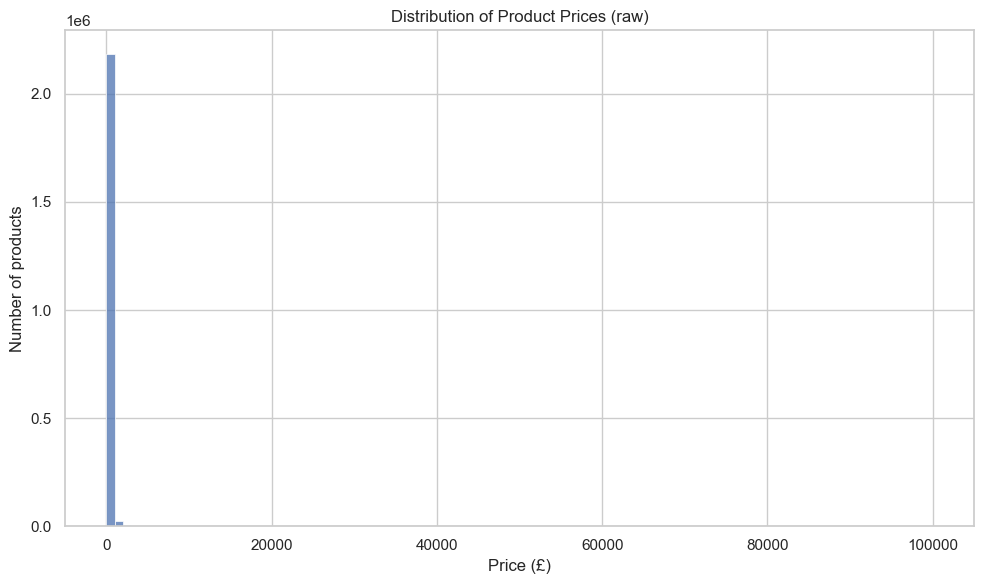

In [11]:
# Histogram - raw price distribution
plt.figure(figsize=(10, 6))
sns.histplot(df["price"], bins=100)
plt.title("Distribution of Product Prices (raw)")
plt.xlabel("Price (£)")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()


**Why this histogram is hard to read:** the vast majority of products have a relatively low price, but a small minority of very expensive products (outliers) stretch the x-axis over an enormous range. All the bars end up compressed near zero, and the actual shape of the distribution becomes impossible to see.

**Two possible solutions:**
1. Zoom in on the price range that covers most products (e.g. filter below the 99th percentile).
2. Use a logarithmic scale on the x-axis.

Both are applied below:

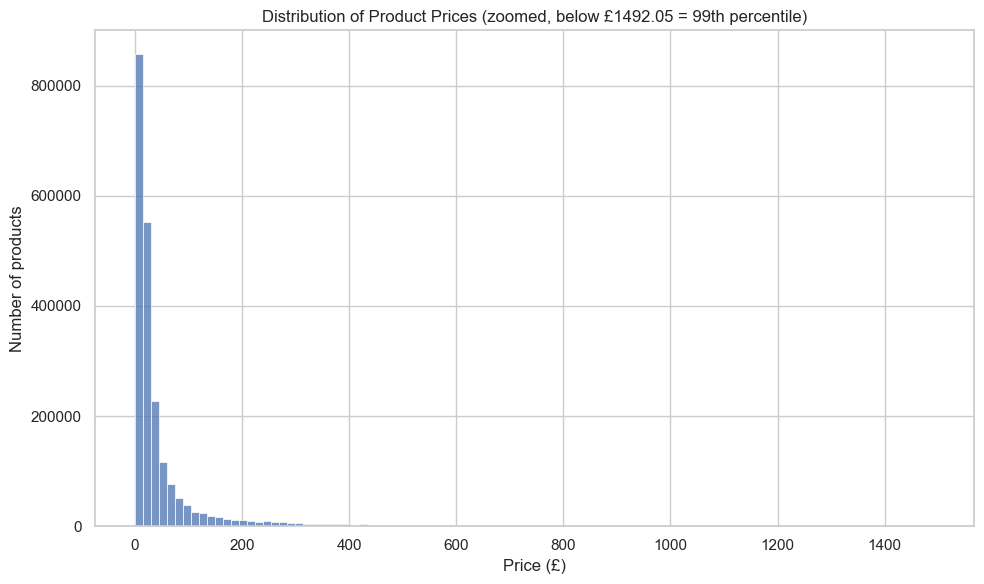

In [12]:
# Solution 1: zoom on the range covering most products (below the 99th percentile)
price_99th = df["price"].quantile(0.99)

plt.figure(figsize=(10, 6))
sns.histplot(df[df["price"] <= price_99th]["price"], bins=100)
plt.title(f"Distribution of Product Prices (zoomed, below £{price_99th:.2f} = 99th percentile)")
plt.xlabel("Price (£)")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()


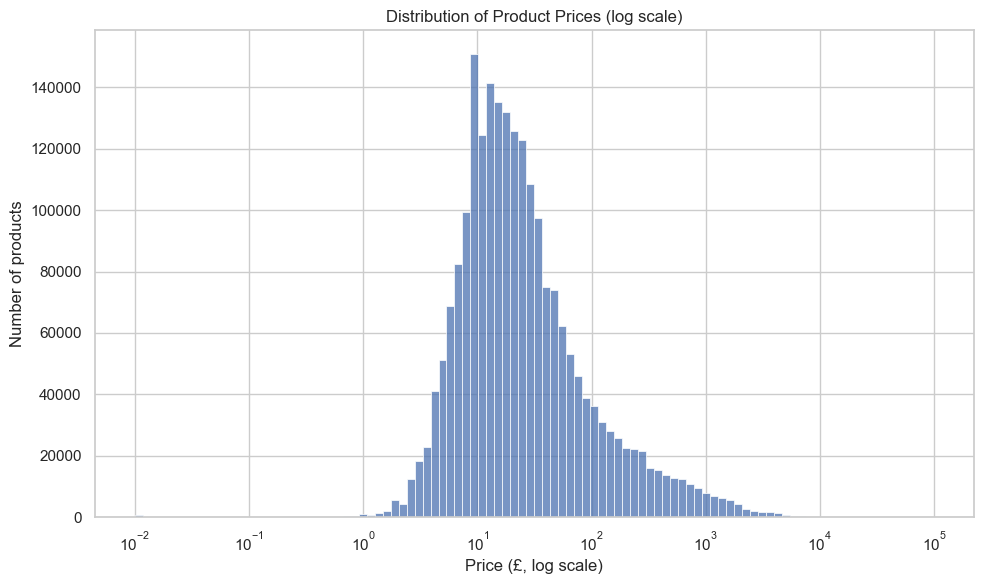

In [13]:
# Solution 2: log scale on the x-axis (keeps all data points, including outliers)
plt.figure(figsize=(10, 6))
sns.histplot(df["price"], bins=100, log_scale=True)
plt.title("Distribution of Product Prices (log scale)")
plt.xlabel("Price (£, log scale)")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()


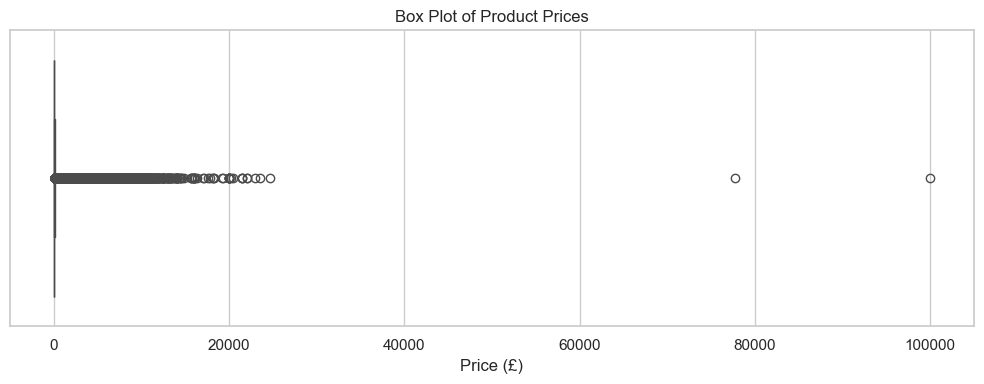

In [14]:
# Box plot - spread and outliers
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["price"])
plt.title("Box Plot of Product Prices")
plt.xlabel("Price (£)")
plt.tight_layout()
plt.show()


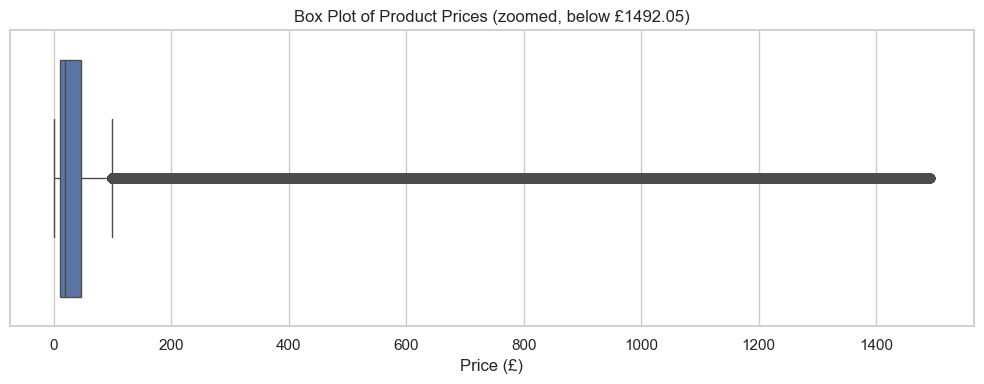

In [15]:
# Zoomed box plot (below 99th percentile) to see the box itself more clearly
plt.figure(figsize=(10, 4))
sns.boxplot(x=df[df["price"] <= price_99th]["price"])
plt.title(f"Box Plot of Product Prices (zoomed, below £{price_99th:.2f})")
plt.xlabel("Price (£)")
plt.tight_layout()
plt.show()


**Interpretation:**
- Most products fall in a fairly narrow low-price band: the IQR shows the middle 50% of products priced between £10.00 and £47.71, consistent with the zoomed histogram showing a strong concentration of products under roughly £50.
- The box plot shows a very large number of points beyond the upper whisker — a long tail of outliers stretching all the way to £100,000. In business terms, this cluster likely mixes two different populations: (1) genuine premium/high-end products (electronics, appliances, luxury goods), and (2) data entry errors or placeholder prices (like the exact £100,000 maximum) that should be cleaned before using price as a variable in further analysis or pricing models.


---
## Part 3: Unpacking Product Ratings

**Business Question:** How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

**Note:** the rating column is called `stars` in this dataset.


### 1. Measures of Centrality

In [16]:
rating_mean = df["stars"].mean()
rating_median = df["stars"].median()
rating_mode = df["stars"].mode().iloc[0]

print(f"Mean rating:   {rating_mean:.2f}")
print(f"Median rating: {rating_median:.2f}")
print(f"Mode rating:   {rating_mode:.2f}")


Mean rating:   2.03
Median rating: 0.00
Mode rating:   0.00


**Interpretation:**
- The mean rating across *all* products is only 2.03 — but this is misleading on its own: **1,174,420 products (52.8% of the catalog) have a rating of 0**, meaning they have never been reviewed rather than being poorly rated. The median and mode of 0 confirm that "no reviews yet" is actually the single most common state in this dataset.
- Once we look only at the ~1.05M products that *have* at least one review, the picture flips: the average rating jumps to roughly **4.3/5**, confirming the well-known marketplace pattern of a strong positive bias among products that do get reviewed.


### 2. Measures of Dispersion

In [17]:
rating_var = df["stars"].var()
rating_std = df["stars"].std()
rating_q1 = df["stars"].quantile(0.25)
rating_q3 = df["stars"].quantile(0.75)
rating_iqr = rating_q3 - rating_q1

print(f"Variance: {rating_var:.3f}")
print(f"Std dev:  {rating_std:.3f}")
print(f"IQR:      {rating_iqr:.2f} (Q1={rating_q1:.2f}, Q3={rating_q3:.2f})")


Variance: 4.776
Std dev:  2.185
IQR:      4.40 (Q1=0.00, Q3=4.40)


**Interpretation:**
- Looking at the overall `stars` column (variance 4.776, std dev 2.185, IQR 4.40 with Q1=0/Q3=4.40), the dispersion looks very large — but this is once again an artifact of mixing "no reviews" (0) with actual ratings, not genuine inconsistency in customer opinions. The IQR spanning from 0 to 4.40 is really capturing the split between unrated and rated products rather than disagreement among reviewers.
- Among rated products specifically, ratings are much more consistent and skew high (see skewness/kurtosis below), so the *actual* customer sentiment is far more homogeneous than the raw dispersion numbers on the full column suggest.


### 3. Shape of the Distribution

In [18]:
# Note: many products have stars = 0 (no ratings yet). Consider whether to exclude them
# for a cleaner picture of *actual customer sentiment* vs "no reviews yet".
print("Products with 0 stars (likely no reviews):", (df["stars"] == 0).sum())

rated_products = df[df["stars"] > 0]["stars"]

skewness = stats.skew(rated_products)
kurt = stats.kurtosis(rated_products)  # excess kurtosis (0 = normal distribution)

print(f"Skewness (rated products only): {skewness:.3f}")
print(f"Kurtosis (rated products only): {kurt:.3f}")


Products with 0 stars (likely no reviews): 1174420
Skewness (rated products only): -2.358
Kurtosis (rated products only): 9.452


**Interpretation:**
- The skewness of rated products is **-2.358**, a strongly negative value confirming the distribution is stretched toward the left: the bulk of ratings sit high (near 4-5 stars) with a long tail of lower ratings, exactly the pattern typical of review platforms.
- The kurtosis is **9.452**, far above the 0 baseline of a normal distribution. This confirms a sharply peaked distribution: ratings are tightly concentrated around a common high value, with heavier tails than a normal curve would predict (i.e., more extreme low outlier ratings than "random noise" would produce).


### 4. Visualizations

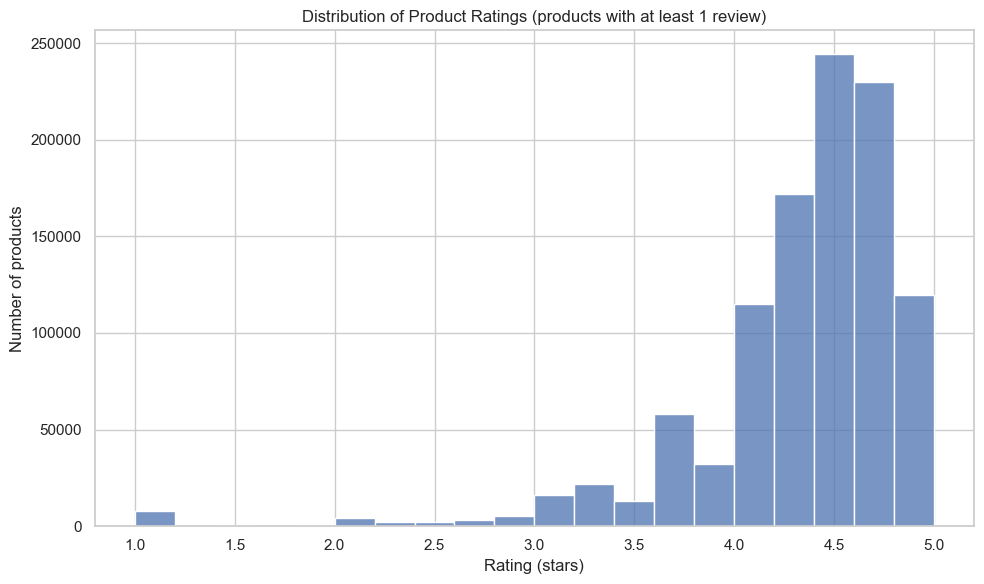

In [19]:
plt.figure(figsize=(10, 6))
sns.histplot(rated_products, bins=20)
plt.title("Distribution of Product Ratings (products with at least 1 review)")
plt.xlabel("Rating (stars)")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()


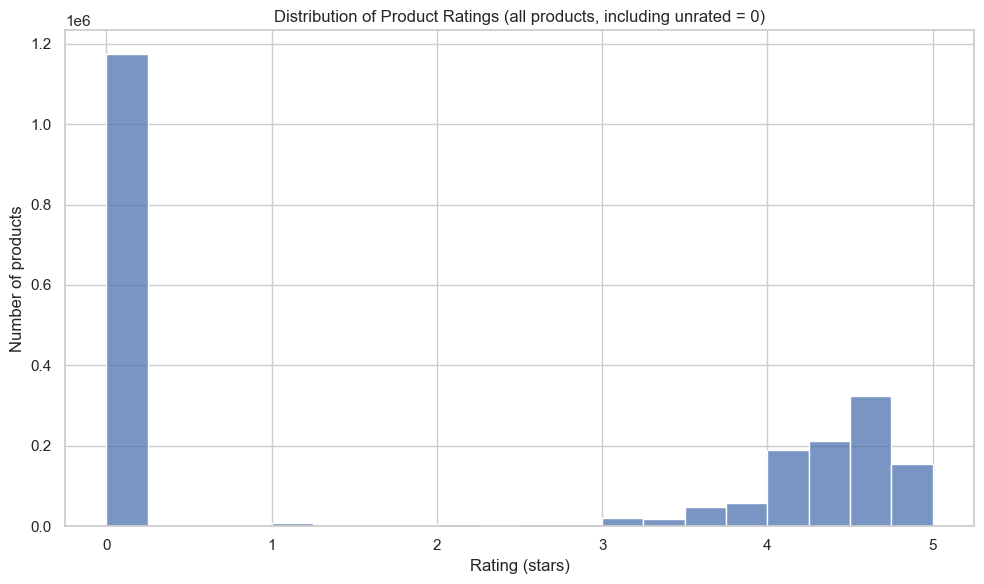

In [20]:
plt.figure(figsize=(10, 6))
sns.histplot(df["stars"], bins=20)
plt.title("Distribution of Product Ratings (all products, including unrated = 0)")
plt.xlabel("Rating (stars)")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()


**Interpretation:**
- Among rated products, ratings cluster heavily near the top of the scale (4-5 stars), consistent with the strongly negative skewness — this confirms the bias toward high ratings typical of marketplace reviews.
- The second histogram (all products) shows a massive spike at 0 — **over half the catalog (52.8%)** — which represents products with no reviews yet, not products that were rated poorly. Any business reporting on "average customer satisfaction" must explicitly separate these two populations, or risk drastically understating how well-reviewed products actually perform.


---
## Business Report - Summary

### Product Categories
- Top 5 categories by listing volume: **Sports & Outdoors** (826,076 listings, 37.16%), Skin Care (18,755, 0.84%), Fragrances (18,563, 0.84%), Make-up (18,453, 0.83%), Manicure & Pedicure Products (17,212, 0.77%).
- Catalog concentration is extreme: one category alone accounts for over a third of all listings, more than 44x the size of the next-largest category, while the rest of the catalog is a long tail of small, fragmented categories.
- **Business recommendation:** treat "Sports & Outdoors" as its own strategic segment given its scale — it likely drives disproportionate traffic, warehousing needs, and competitive pressure on price. Before acting on this, validate whether this concentration is a genuine market signal or a categorization/data quality issue (a catch-all bucket), since this materially changes the recommended action (inventory prioritization vs. a data cleaning fix).

### Pricing
- Mean price £94.26 vs. median £19.90 vs. mode £9.99: the mean is ~4.7x the median, indicating a strongly right-skewed distribution dominated by a low number of expensive products.
- Price dispersion is very high (std dev £360.62) and driven almost entirely by outliers: the middle 50% of products (IQR) sit between £10.00 and £47.71, while the full range stretches to a highly suspicious £100,000 maximum and a £0 minimum.
- **Business recommendation:** for pricing strategy and positioning, the median (£19.90) and mode (£9.99) are far more representative of what a typical shopper pays than the mean. Competitive pricing and inventory decisions should be anchored on the £10-£48 IQR band where most products actually sit. Separately, the £0 and £100,000 extreme values should be cleaned/investigated (likely missing-price placeholders and a data entry error) before this price field is used in any pricing model or reporting.

### Ratings
- The raw average rating (2.03) is misleading: 52.8% of products (1,174,420) have never been reviewed (rating = 0). Among the ~1.05M products that have been reviewed, the average rating is closer to **4.3/5**, with strongly negative skewness (-2.358) and high kurtosis (9.452), confirming ratings cluster tightly near the top of the scale.
- Customer feedback, where it exists, is consistently positive and fairly homogeneous — this is not a catalog with widespread quality complaints, but one with a very large share of products that simply haven't accumulated reviews yet.
- **Business recommendation:** prioritize review-generation efforts (post-purchase prompts, review incentives) on the "no reviews yet" segment, since the ratings ceiling among reviewed products suggests strong underlying product quality that isn't being reflected in visible social proof for over half the catalog. Any customer-facing "average rating" metric should explicitly exclude or flag unrated products rather than silently averaging them in as low scores.
